<a href="https://colab.research.google.com/github/Siddhi-Salunkhe/ML-Practicals/blob/main/9.Basic_SVM_Experiment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**GitHub Repository:** https://github.com/Siddhi-Salunkhe/ML-Practicals

# Experiment: Support Vector Machine (SVM)



**Aim:** To implement Linear, RBF and Polynomial SVM, visualize support vectors and decision boundaries, and try different C and gamma values.

**Prepared and Submitted by** : **Siddhi salunkhe**

**PRN:** **24068111242052**

**Subject: Machine Learning**


**Library:** Scikit-learn and Matplotlib

## 1. Import libraries and create dataset

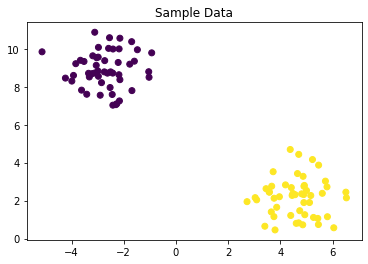

In [ ]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Create simple dataset
X, y = make_blobs(n_samples=100, centers=2, random_state=42)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

plt.scatter(X[:, 0], X[:, 1], c=y)
plt.title("Sample Data")
plt.show()

## 2. Train three SVM models

In [ ]:
# Linear SVM
linear = SVC(kernel="linear", C=1)
linear.fit(X_train, y_train)

# RBF SVM
rbf = SVC(kernel="rbf", C=1, gamma="scale")
rbf.fit(X_train, y_train)

# Polynomial SVM
poly = SVC(kernel="poly", degree=3, C=1)
poly.fit(X_train, y_train)

print("Linear Accuracy:", accuracy_score(y_test, linear.predict(X_test)))
print("RBF Accuracy:", accuracy_score(y_test, rbf.predict(X_test)))
print("Polynomial Accuracy:", accuracy_score(y_test, poly.predict(X_test)))

Linear Accuracy: 1.0
RBF Accuracy: 1.0
Polynomial Accuracy: 1.0


## 3. Visualize decision boundary and support vectors

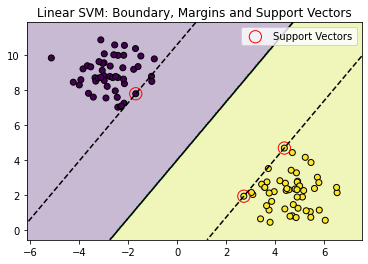

In [ ]:
# Select a model to visualize
model = linear

# Make a grid for plotting
import numpy as np
xx, yy = np.meshgrid(
    np.linspace(X[:, 0].min()-1, X[:, 0].max()+1, 200),
    np.linspace(X[:, 1].min()-1, X[:, 1].max()+1, 200)
)

Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

plt.contourf(xx, yy, Z, alpha=0.3)
plt.scatter(X[:, 0], X[:, 1], c=y, edgecolors="k")
plt.scatter(model.support_vectors_[:, 0],
            model.support_vectors_[:, 1],
            s=150, facecolors="none", edgecolors="red",
            label="Support Vectors")

# Show margin lines for linear SVM
if model.kernel == "linear":
    decision = model.decision_function(np.c_[xx.ravel(), yy.ravel()])
    decision = decision.reshape(xx.shape)
    plt.contour(xx, yy, decision, levels=[-1, 0, 1],
                colors="black", linestyles=["--", "-", "--"])

plt.title("Linear SVM: Boundary, Margins and Support Vectors")
plt.legend()
plt.show()

**Try another kernel:** In the visualization cell, change `model = linear` to `model = rbf` or `model = poly` and run the cell again. The red circles show support vectors. Margin lines are drawn for the linear SVM.

## 4. Try different C and gamma values

In [ ]:
# Try different C values
for c in [0.1, 1, 10]:
    model = SVC(kernel="rbf", C=c, gamma="scale")
    model.fit(X_train, y_train)
    print("C =", c, "Accuracy =", accuracy_score(y_test, model.predict(X_test)))

# Try different gamma values
for g in [0.1, 1, 10]:
    model = SVC(kernel="rbf", C=1, gamma=g)
    model.fit(X_train, y_train)
    print("Gamma =", g, "Accuracy =", accuracy_score(y_test, model.predict(X_test)))

C = 0.1 Accuracy = 1.0
C = 1 Accuracy = 1.0
C = 10 Accuracy = 1.0
Gamma = 0.1 Accuracy = 1.0
Gamma = 1 Accuracy = 1.0
Gamma = 10 Accuracy = 0.9


## Observations
1. SVM separates data into different classes.
2. Linear SVM uses a straight decision boundary.
3. RBF and Polynomial kernels can form curved decision boundaries.
4. Support vectors are the important data points near the boundary.
5. C and gamma values can change the model accuracy.

## Result
Linear, RBF and Polynomial SVM models were trained. Their accuracy was compared, support vectors and decision boundaries were visualized, and different C and gamma values were tested.